<a href="https://colab.research.google.com/github/najeeb160/explainable-nids/blob/main/notebooks/Phase1_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Phase 1 — Dataset Exploration & Quality Audit**
**Dataset:** NF-UNSW-NB15-v3 (NetFlow v3 records of the UNSW-NB15 capture)

**Gate criteria (all must pass):**

1. Full CSV loaded: exactly 2,365,424 rows × 55 columns
2. Label/Attack columns perfectly consistent
3. Attack ratio ≈ 5.40% (paper value)
4. Data quality audit: missing, inf, duplicates, sentinel values
5. Report-ready figures saved to Drive
6. Findings markdown saved to Drive
7. Restart & Run All → zero errors

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

sns.set_theme(style="whitegrid")

from google.colab import drive
drive.mount('/content/drive')

DRIVE_PROJECT = '/content/drive/MyDrive/NIDS_Project'
FIG_DIR = os.path.join(DRIVE_PROJECT, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

zips = glob.glob(f'{DRIVE_PROJECT}/*.zip')
assert len(zips) == 1, f"Expected exactly 1 zip in {DRIVE_PROJECT}, found: {zips}"

os.makedirs('data', exist_ok=True)   # ← THE FIX: create data/ before unzip

!unzip -d data/NF-UNSW-NB15-v3 -j -o "{zips[0]}"

csv_path = 'data/NF-UNSW-NB15-v3/NF-UNSW-NB15-v3.csv'
assert os.path.exists(csv_path), "❌ CSV missing after unzip"
print("Environment ready ✅")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archive:  /content/drive/MyDrive/NIDS_Project/f7546561558c07c5_NFV3DATA-A11964_A11964.zip
  inflating: data/NF-UNSW-NB15-v3/FurtherInformation.txt  
  inflating: data/NF-UNSW-NB15-v3/bag-info.txt  
 extracting: data/NF-UNSW-NB15-v3/bagit.txt  
  inflating: data/NF-UNSW-NB15-v3/manifest-sha1.txt  
  inflating: data/NF-UNSW-NB15-v3/tagmanifest-sha1.txt  
  inflating: data/NF-UNSW-NB15-v3/NF-UNSW-NB15-v3.csv  
  inflating: data/NF-UNSW-NB15-v3/NetFlow_v3_Features.csv  
Environment ready ✅


In [2]:
%%time
df = pd.read_csv(csv_path)
print(f"Loaded {len(df):,} rows × {df.shape[1]} columns")

Loaded 2,365,424 rows × 55 columns
CPU times: user 15.3 s, sys: 4.17 s, total: 19.5 s
Wall time: 19.8 s


In [3]:
EXPECTED_ROWS, EXPECTED_COLS = 2_365_424, 55
assert df.shape == (EXPECTED_ROWS, EXPECTED_COLS), \
    f"❌ Shape mismatch: got {df.shape}, expected ({EXPECTED_ROWS}, {EXPECTED_COLS})"
print(f"✅ Shape gate passed: {df.shape[0]:,} rows × {df.shape[1]} columns — matches the paper exactly")

✅ Shape gate passed: 2,365,424 rows × 55 columns — matches the paper exactly


In [4]:
# Rule: Label==0  ⟺  Attack=='Benign'
mismatch = ((df['Label'] == 0) != (df['Attack'] == 'Benign')).sum()
assert mismatch == 0, f"❌ Label/Attack disagree on {mismatch} rows"
print("✅ Label and Attack columns are perfectly consistent")
print(df['Label'].value_counts().rename({0: 'Benign (0)', 1: 'Attack (1)'}))

✅ Label and Attack columns are perfectly consistent
Label
Benign (0)    2237731
Attack (1)     127693
Name: count, dtype: int64


In [5]:
attack_ratio = df['Label'].mean()
print(f"Attack ratio: {attack_ratio:.4%}")
assert 0.05 < attack_ratio < 0.06, "❌ Attack ratio deviates from the paper's 5.40%"
print("✅ Attack ratio matches the paper (~5.40%)")

Attack ratio: 5.3983%
✅ Attack ratio matches the paper (~5.40%)


Attack
Benign            2237731
Exploits            42748
Fuzzers             33816
Generic             19651
Reconnaissance      17074
DoS                  5980
Backdoor             4659
Shellcode            2381
Analysis             1226
Worms                 158
Name: count, dtype: int64

Unique categories: 10


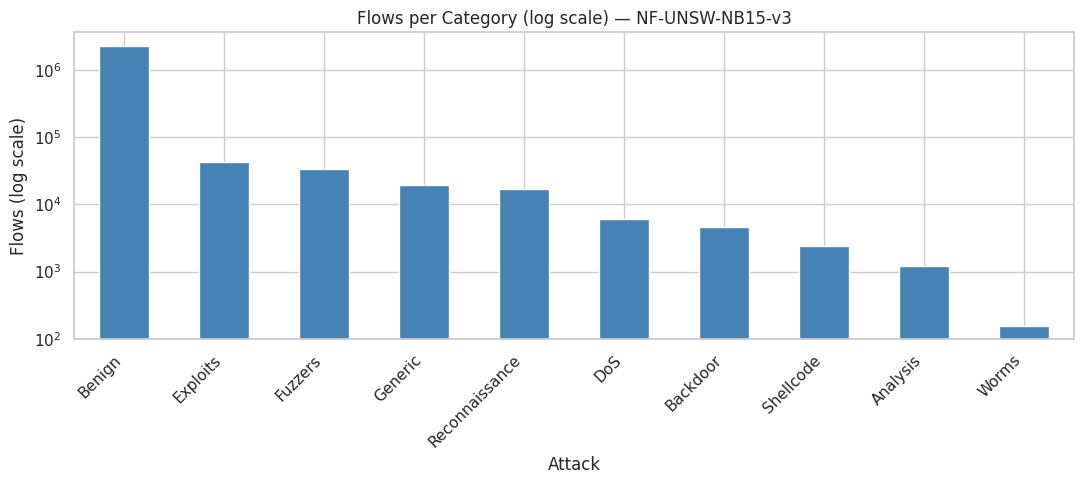

Figure saved: /content/drive/MyDrive/NIDS_Project/figures/phase1_category_distribution.png


In [6]:
counts = df['Attack'].value_counts()
print(counts)
print(f"\nUnique categories: {df['Attack'].nunique()}")

ax = counts.plot(kind='bar', logy=True, figsize=(11, 5), color='steelblue')
ax.set_title("Flows per Category (log scale) — NF-UNSW-NB15-v3")
ax.set_ylabel("Flows (log scale)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
fig_path = f"{FIG_DIR}/phase1_category_distribution.png"
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Figure saved: {fig_path}")

In [7]:
missing = df.isna().sum()
print("=== Missing values ===")
print(missing[missing > 0] if missing.sum() > 0 else "None ✅")

num_df = df.select_dtypes(include=[np.number])
inf_counts = np.isinf(num_df).sum()
print("\n=== Columns containing inf ===")
print(inf_counts[inf_counts > 0] if inf_counts.sum() > 0 else "None ✅")

=== Missing values ===
SRC_TO_DST_SECOND_BYTES    63425
dtype: int64

=== Columns containing inf ===
SRC_TO_DST_SECOND_BYTES     59068
DST_TO_SRC_SECOND_BYTES    122493
dtype: int64


In [8]:
dup_full = df.duplicated().sum()
print(f"Fully duplicated rows (all 55 cols): {dup_full:,}")

dup_no_ts = df.drop(columns=['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS']).duplicated().sum()
print(f"Duplicates ignoring timestamps:      {dup_no_ts:,}")
print("\nNote: repeated flows are genuine recurring traffic (e.g., DNS queries),")
print("NOT data errors — we do NOT drop them (GraphIDS keeps them too).")

Fully duplicated rows (all 55 cols): 14,815
Duplicates ignoring timestamps:      24,417

Note: repeated flows are genuine recurring traffic (e.g., DNS queries),
NOT data errors — we do NOT drop them (GraphIDS keeps them too).


In [9]:
sentinel_cols = ['L4_SRC_PORT', 'L4_DST_PORT', 'ICMP_TYPE', 'ICMP_IPV4_TYPE',
                 'DNS_QUERY_ID', 'DNS_QUERY_TYPE', 'DNS_TTL_ANSWER',
                 'FTP_COMMAND_RET_CODE', 'MIN_TTL', 'MAX_TTL']
print(f"{'Column':>22} | {'rows with -1':>13} | share")
print("-" * 50)
for c in sentinel_cols:
    n = (df[c] == -1).sum()
    print(f"{c:>22} | {n:>13,} | {n/len(df):.2%}")

                Column |  rows with -1 | share
--------------------------------------------------
           L4_SRC_PORT |             0 | 0.00%
           L4_DST_PORT |             0 | 0.00%
             ICMP_TYPE |             0 | 0.00%
        ICMP_IPV4_TYPE |             0 | 0.00%
          DNS_QUERY_ID |             0 | 0.00%
        DNS_QUERY_TYPE |             0 | 0.00%
        DNS_TTL_ANSWER |             0 | 0.00%
  FTP_COMMAND_RET_CODE |             0 | 0.00%
               MIN_TTL |             0 | 0.00%
               MAX_TTL |             0 | 0.00%


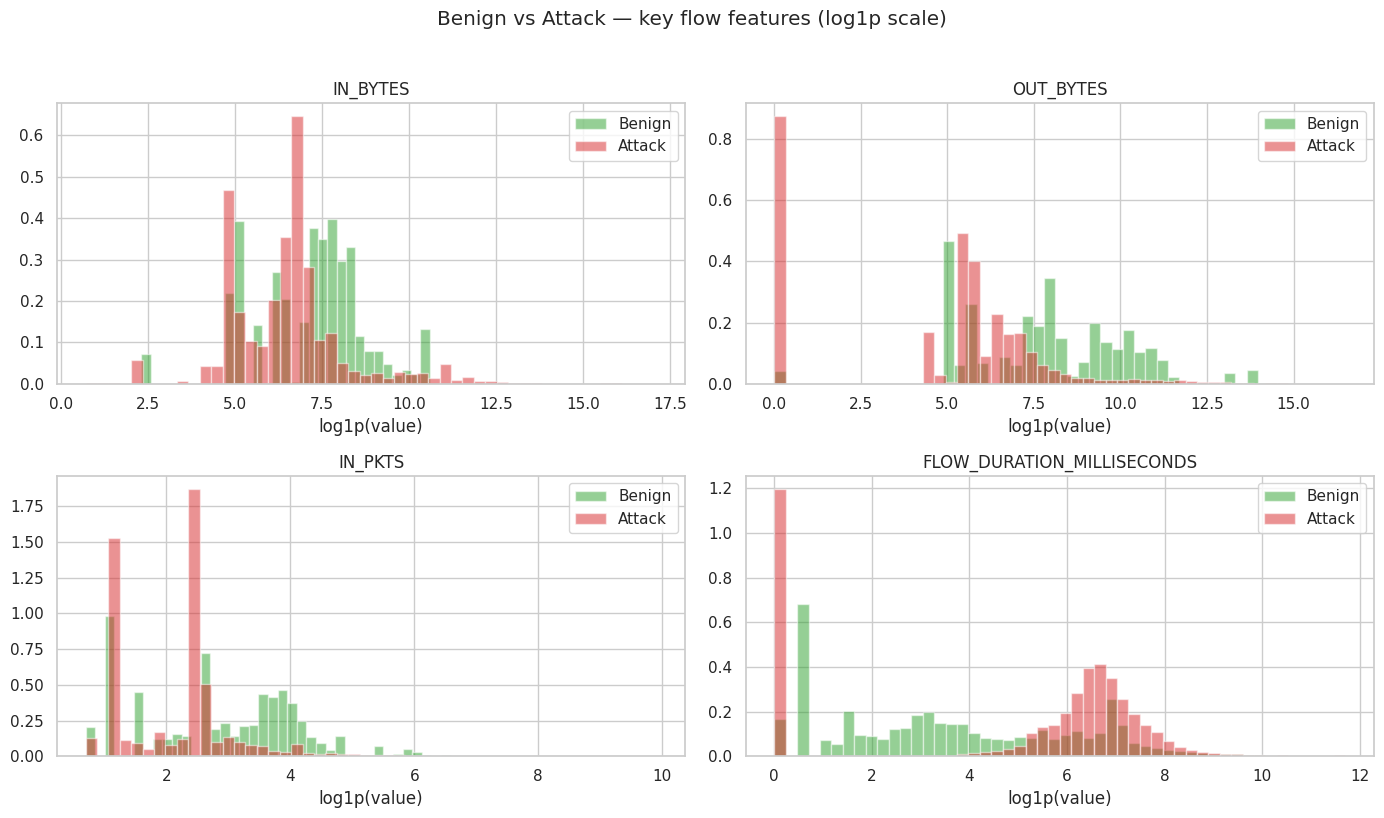

Figure saved: /content/drive/MyDrive/NIDS_Project/figures/phase1_feature_distributions.png


In [10]:
features = ['IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'FLOW_DURATION_MILLISECONDS']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, feat in zip(axes.flat, features):
    for label, name, color in [(0, 'Benign', 'tab:green'), (1, 'Attack', 'tab:red')]:
        vals = np.log1p(df.loc[df['Label'] == label, feat])
        ax.hist(vals, bins=50, alpha=0.5, label=name, color=color, density=True)
    ax.set_title(feat)
    ax.set_xlabel("log1p(value)")
    ax.legend()
plt.suptitle("Benign vs Attack — key flow features (log1p scale)", y=1.02)
plt.tight_layout()
fig_path = f"{FIG_DIR}/phase1_feature_distributions.png"
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure saved: {fig_path}")

In [11]:
proto_map = {6: 'TCP', 17: 'UDP', 1: 'ICMP'}
proto_name = df['PROTOCOL'].map(proto_map).fillna('Other')

ct = pd.crosstab(proto_name, df['Label'], normalize='index') * 100
ct.columns = ['Benign %', 'Attack %']
print("Attack share by transport protocol:")
print(ct.round(2))

raw = pd.crosstab(proto_name, df['Label'])
print("\nRaw counts:")
print(raw)

Attack share by transport protocol:
          Benign %  Attack %
PROTOCOL                    
ICMP         70.82     29.18
Other        39.92     60.08
TCP          94.87      5.13
UDP          94.06      5.94

Raw counts:
Label           0      1
PROTOCOL                
ICMP          284    117
Other        1276   1920
TCP       1712682  92588
UDP        523489  33068


In [12]:
print("Top 10 destination ports — BENIGN:")
print(df.loc[df['Label'] == 0, 'L4_DST_PORT'].value_counts().head(10))

print("\nTop 10 destination ports — ATTACK:")
print(df.loc[df['Label'] == 1, 'L4_DST_PORT'].value_counts().head(10))

Top 10 destination ports — BENIGN:
L4_DST_PORT
21      470213
53      366530
80      179164
6881    115744
5190    110030
111      78107
25       75488
22       46318
143      44638
0         1560
Name: count, dtype: int64

Top 10 destination ports — ATTACK:
L4_DST_PORT
80      22410
179     18760
53      13598
21      12906
111      9200
520      8637
445      5912
25       4939
514      3501
1723     3142
Name: count, dtype: int64


Capture span : 2015-01-22 11:49:36.907000  →  2015-02-18 12:29:24.927000
Days with traffic: 3


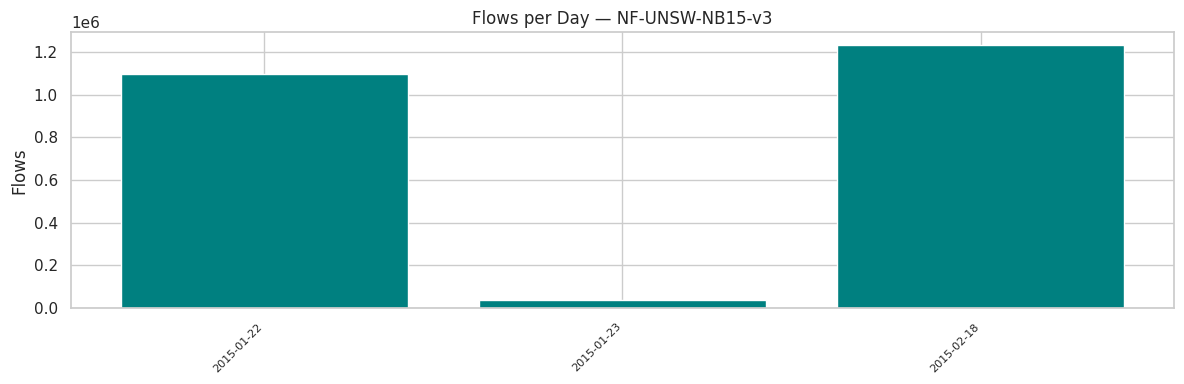

Figure saved: /content/drive/MyDrive/NIDS_Project/figures/phase1_temporal_coverage.png


In [13]:
start_ts = pd.to_datetime(df['FLOW_START_MILLISECONDS'], unit='ms')
per_day = start_ts.dt.date.value_counts().sort_index()

print(f"Capture span : {start_ts.min()}  →  {start_ts.max()}")
print(f"Days with traffic: {len(per_day)}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(per_day)), per_day.values, color='teal')
ax.set_xticks(range(len(per_day)))
ax.set_xticklabels([str(d) for d in per_day.index], rotation=45, ha='right', fontsize=8)
ax.set_title("Flows per Day — NF-UNSW-NB15-v3")
ax.set_ylabel("Flows")
plt.tight_layout()
fig_path = f"{FIG_DIR}/phase1_temporal_coverage.png"
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Figure saved: {fig_path}")

In [14]:
attack_ratio = df['Label'].mean()
n_attack_cats = df.loc[df['Attack'] != 'Benign', 'Attack'].nunique()

missing_summary = missing[missing > 0]
missing_line = ", ".join(f"{c} ({n:,})" for c, n in missing_summary.items()) if missing_summary.sum() > 0 else "none"

inf_summary = inf_counts[inf_counts > 0]
inf_line = ", ".join(f"{c} ({n:,})" for c, n in inf_summary.items()) if inf_summary.sum() > 0 else "none"

proto_line = ", ".join(f"{p} {v:.1f}%" for p, v in ct['Attack %'].sort_values(ascending=False).items())

findings = f"""# Phase 1 — Findings (NF-UNSW-NB15-v3)
- Generated: {datetime.now().isoformat()}
- Shape: {len(df):,} rows × {df.shape[1]} cols — matches paper (2,365,424) ✅
- Attack ratio: {attack_ratio:.2%} (paper: 5.40%) ✅
- Categories: Benign + {n_attack_cats} attack types = {df['Attack'].nunique()} total
- Missing values (NaN): {missing_line}
- inf values: {inf_line}
- GraphIDS preprocessing (verified in utils/dataloaders.py): inf → NaN → 0, so both anomalies are neutralized before MinMax scaling
- Fully duplicated rows: {dup_full:,}; ignoring timestamps: {dup_no_ts:,} (genuine recurring traffic, kept — GraphIDS does not deduplicate)
- No -1 sentinel values in the 10 protocol-specific columns checked; 0 acts as the not-applicable value ({int((df['L4_DST_PORT'] == 0).sum()):,} flows with L4_DST_PORT = 0, e.g. ICMP/other non-TCP-UDP)
- Attack share by protocol: {proto_line} — rare protocols are disproportionately targeted
- Capture span: {start_ts.min()} → {start_ts.max()} across {len(per_day)} active days
- Figures saved: phase1_category_distribution.png, phase1_feature_distributions.png, phase1_temporal_coverage.png
"""

path = f'{DRIVE_PROJECT}/phase1_findings.md'
with open(path, 'w') as f:
    f.write(findings)
print(f"Findings saved to {path} ✅")
print(findings)

Findings saved to /content/drive/MyDrive/NIDS_Project/phase1_findings.md ✅
# Phase 1 — Findings (NF-UNSW-NB15-v3)
- Generated: 2026-10-29T09:28:24.017897
- Shape: 2,365,424 rows × 55 cols — matches paper (2,365,424) ✅
- Attack ratio: 5.40% (paper: 5.40%) ✅
- Categories: Benign + 9 attack types = 10 total
- Missing values (NaN): SRC_TO_DST_SECOND_BYTES (63,425)
- inf values: SRC_TO_DST_SECOND_BYTES (59,068), DST_TO_SRC_SECOND_BYTES (122,493)
- GraphIDS preprocessing (verified in utils/dataloaders.py): inf → NaN → 0, so both anomalies are neutralized before MinMax scaling
- Fully duplicated rows: 14,815; ignoring timestamps: 24,417 (genuine recurring traffic, kept — GraphIDS does not deduplicate)
- No -1 sentinel values in the 10 protocol-specific columns checked; 0 acts as the not-applicable value (3,530 flows with L4_DST_PORT = 0, e.g. ICMP/other non-TCP-UDP)
- Attack share by protocol: Other 60.1%, ICMP 29.2%, UDP 5.9%, TCP 5.1% — rare protocols are disproportionately targeted
- Captu

#✅ Gate 1 Checklist
 [✔] Restart & Run All → zero errors  
 [✔] Shape gate: 2,365,424 × 55  
 [✔] Label/Attack consistency: 0 mismatches  
 [✔] Attack ratio ≈ 5.40%  
 [✔] Quality audit done: missing / inf / duplicates / sentinels  
 [✔] 3 figures saved to Drive (figures/)  
 [✔] phase1_findings.md saved to Drive